In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('loan_approval_data.csv')

In [3]:
df.head()
df.info()
df.isnull().sum()
df.describe()



<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


handle missing values


In [4]:
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['float64']).columns

C:\Users\vaishnavi\AppData\Local\Temp\ipykernel_20144\1257646291.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [5]:
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy='mean')
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])



In [6]:
cat_imp = SimpleImputer(strategy='most_frequent')
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])


In [7]:
df.head

<bound method NDFrame.head of      Applicant_ID  Applicant_Income  Coapplicant_Income Employment_Status  \
0             1.0      17795.000000              1387.0          Salaried   
1             2.0       2860.000000              2679.0          Salaried   
2             3.0       7390.000000              2106.0          Salaried   
3             4.0      13964.000000              8173.0          Salaried   
4             5.0      13284.000000              4223.0     Self-employed   
..            ...               ...                 ...               ...   
995         996.0      10852.571579              9092.0          Salaried   
996         997.0       3279.000000              6356.0     Self-employed   
997         998.0      15192.000000              8433.0          Contract   
998         999.0       9083.000000              7380.0        Unemployed   
999        1000.0      13093.000000              2385.0          Salaried   

      Age Marital_Status  Dependents  Credit_

EDA - EXPLORATORY DATA ANALYSIS

Text(0.5, 1.0, 'Loan Approval Distribution')

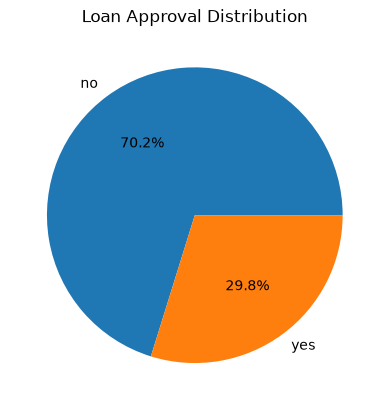

In [8]:
# HOW BALANCED  OUR CLASSES ARE?

classes_count = df['Loan_Approved'].value_counts()
plt.pie (classes_count, labels=["no","yes"], autopct='%1.1f%%')
plt.title("Loan Approval Distribution")

[Text(0, 0, '621'), Text(0, 0, '379')]

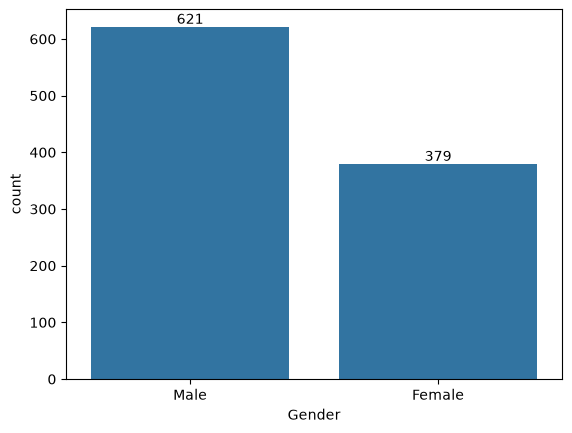

In [9]:
# analyze categories

gender_count = df['Gender'].value_counts()
ax = sns.barplot(gender_count)
ax.bar_label(ax.containers[0])


<Axes: xlabel='Applicant_Income', ylabel='Count'>

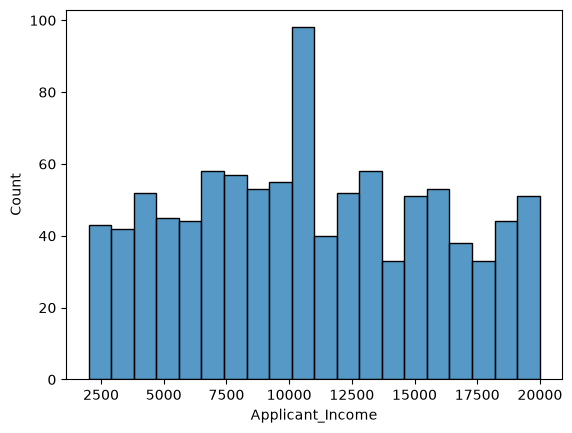

In [10]:
#analyze income
sns.histplot(
    data =df,
    x = 'Applicant_Income',
    bins = 20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

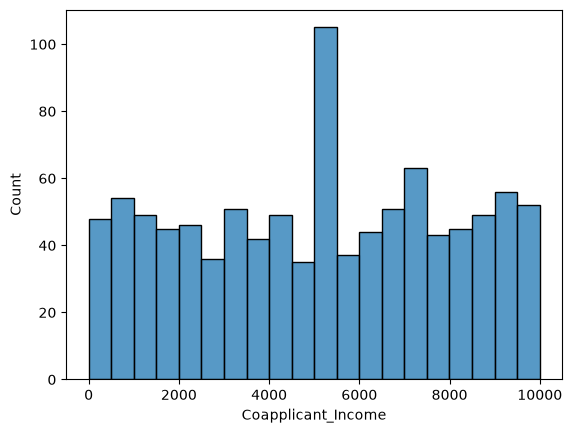

In [11]:
sns.histplot(
    data =df,
    x = 'Coapplicant_Income',
    bins = 20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

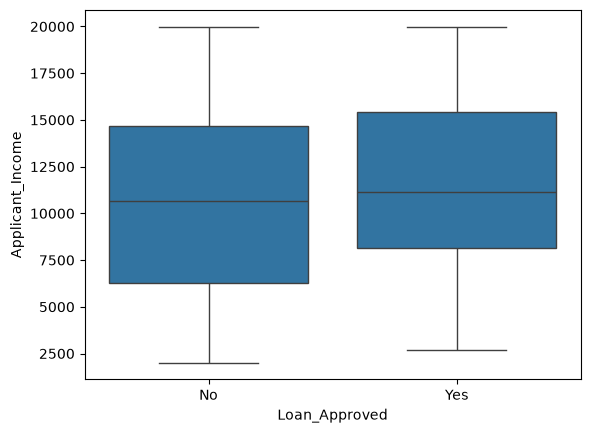

In [12]:
#outliers- box plots
sns.boxplot(
    data=df, 
    x='Loan_Approved',
    y="Applicant_Income"
)

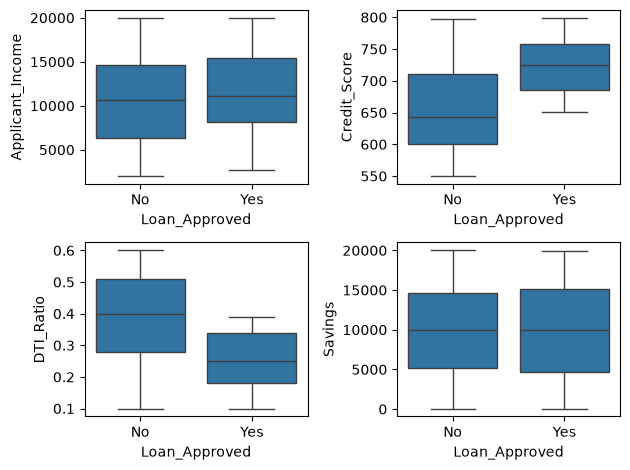

In [13]:
fig,axes =plt.subplots(2,2)
sns.boxplot(ax=axes[0,0], data=df, x='Loan_Approved', y="Applicant_Income")
sns.boxplot(ax=axes[0,1], data=df, x='Loan_Approved', y="Credit_Score")
sns.boxplot(ax=axes[1,0], data=df, x='Loan_Approved', y="DTI_Ratio")
sns.boxplot(ax=axes[1,1], data=df, x='Loan_Approved', y="Savings")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

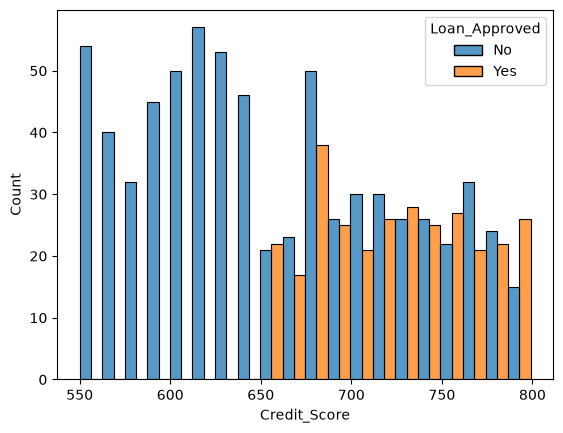

In [14]:
# credit score with loan approval
sns.histplot(
    data=df,
    x='Credit_Score',
    hue='Loan_Approved',
    bins=20,
    multiple='dodge'
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

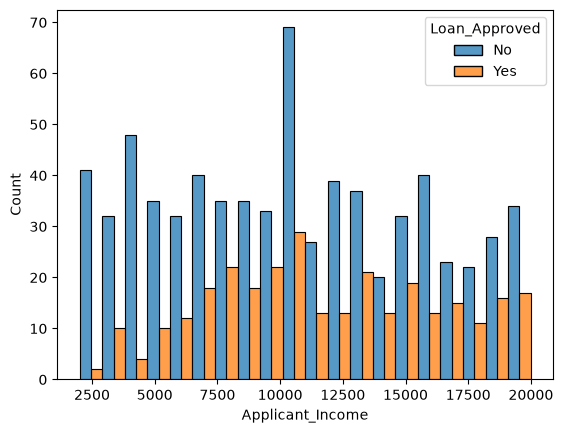

In [15]:
sns.histplot(
    data=df,
    x='Applicant_Income',
    hue='Loan_Approved',
    bins=20,
    multiple='dodge'
)

In [16]:
# Remove applicant id
df = df.drop('Applicant_ID', axis=1)

In [17]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


Encoding

In [18]:
df.head()
df.columns

Index(['Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age',
       'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans',
       'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term',
       'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender',
       'Employer_Category', 'Loan_Approved'],
      dtype='str')

In [19]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])



In [20]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [21]:


cols = [
    "Employment_Status",
    "Gender",
    "Marital_Status",
    "Loan_Purpose",
    "Employer_Category"
]

ohe = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = ohe.fit_transform(df[cols])
encoded_df =pd.DataFrame(encoded, columns=ohe.get_feature_names_out(cols),index=df.index)

df=pd.concat([df.drop(columns=cols),encoded_df], axis=1)



In [22]:
df.head()
df.describe()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Property_Area                    1000 non-null   str    
 12  Education_Level                 

Correlation Heatmap


<Axes: >

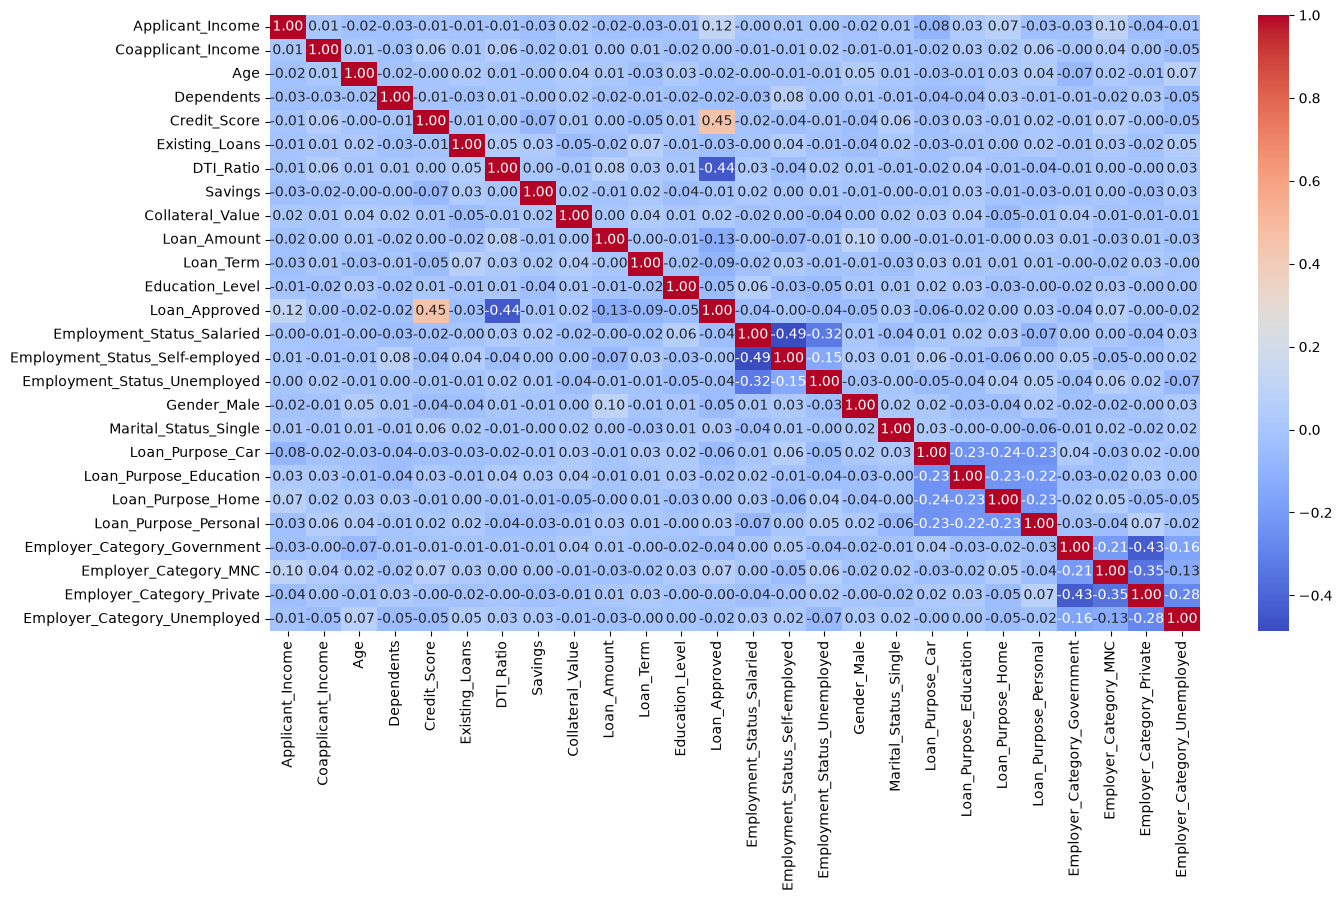

In [23]:
nums_cols = df.select_dtypes(include="number")
corr_matrix = nums_cols.corr()
plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
   
)


In [24]:
 corr_matrix["Loan_Approved"].sort_values(ascending=False)


Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                   -0.052920
Gender_Male                       -0.054342
Loan_Purpose_Car                

Train-Test-Split+ Feature Scaling

In [25]:
x=df.drop("Loan_Approved", axis=1)
y=df["Loan_Approved"]

In [26]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Loan_Approved, dtype: int64

In [27]:
x.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Gender_Male,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [28]:
x_train,x_test,y_train,y_test=train_test_split(x, y, test_size=0.2, random_state=42)

In [29]:
x_train.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Gender_Male,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
29,5890.000000,8041.0,31.000000,0.0,603.000000,0.000000,0.11,11906.0,8150.000000,29287.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
535,4779.000000,529.0,50.000000,0.0,614.000000,0.000000,0.21,5369.0,5430.000000,14786.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
695,10852.571579,8927.0,36.000000,0.0,584.000000,4.000000,0.22,3186.0,24802.792632,20522.825263,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
557,2384.000000,2113.0,39.971579,1.0,726.000000,4.000000,0.34,11882.0,48542.000000,13312.000000,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
836,5228.000000,5249.0,42.000000,1.0,676.033684,1.950526,0.18,17669.0,24802.792632,13906.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [30]:
x_test.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Gender_Male,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
521,13023.0,6675.0,53.000000,3.0,628.0,3.0,0.347263,10051.000000,26309.0,22947.000000,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
737,15917.0,6787.0,42.000000,0.0,588.0,4.0,0.410000,922.000000,13476.0,20522.825263,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
740,7560.0,3530.0,52.000000,3.0,606.0,0.0,0.580000,9940.452632,21795.0,5876.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
660,19022.0,574.0,59.000000,0.0,725.0,4.0,0.410000,1463.000000,44498.0,8433.000000,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
411,4967.0,5797.0,39.971579,3.0,697.0,4.0,0.580000,1095.000000,3017.0,33926.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [31]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)

print("Training columns:", x_train.columns.tolist())
print("Testing columns:", x_test.columns.tolist())

X_train shape: (800, 26)
X_test shape: (200, 26)
Training columns: ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Property_Area', 'Education_Level', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Gender_Male', 'Marital_Status_Single', 'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal', 'Employer_Category_Government', 'Employer_Category_MNC', 'Employer_Category_Private', 'Employer_Category_Unemployed']
Testing columns: ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Property_Area', 'Education_Level', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Gender_Male', 'Marital_Status_Single', 'Loan_Purpose_Car', 

In [32]:
print("Missing values:", x_train.isnull().sum().sum())

print("Text columns:")
print(x_train.select_dtypes(include=['object', 'category']).columns.tolist())

print("Data types:")
print(x_train.dtypes)

Missing values: 0
Text columns:
['Property_Area']
Data types:
Applicant_Income                   float64
Coapplicant_Income                 float64
Age                                float64
Dependents                         float64
Credit_Score                       float64
Existing_Loans                     float64
DTI_Ratio                          float64
Savings                            float64
Collateral_Value                   float64
Loan_Amount                        float64
Loan_Term                          float64
Property_Area                          str
Education_Level                      int64
Employment_Status_Salaried         float64
Employment_Status_Self-employed    float64
Employment_Status_Unemployed       float64
Gender_Male                        float64
Marital_Status_Single              float64
Loan_Purpose_Car                   float64
Loan_Purpose_Education             float64
Loan_Purpose_Home                  float64
Loan_Purpose_Personal              

C:\Users\vaishnavi\AppData\Local\Temp\ipykernel_20144\2590688081.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(x_train.select_dtypes(include=['object', 'category']).columns.tolist())


In [33]:
import pandas as pd

x_train = pd.get_dummies(
    x_train,
    columns=['Property_Area'],
    dtype=int
)

x_test = pd.get_dummies(
    x_test,
    columns=['Property_Area'],
    dtype=int
)

x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_Scaled = scaler.fit_transform(x_train)
x_test_Scaled = scaler.transform(x_test)

In [35]:
x_train_Scaled

array([[-1.01234556e+00,  1.02716377e+00, -8.22511453e-01, ...,
         1.57906611e+00, -4.80384461e-01, -1.05395348e+00],
       [-1.23639141e+00, -1.59187898e+00,  9.15886794e-01, ...,
        -6.33285708e-01, -4.80384461e-01,  9.48808479e-01],
       [-1.15862490e-02,  1.33606578e+00, -3.65038230e-01, ...,
        -6.33285708e-01,  2.08166600e+00, -1.05395348e+00],
       ...,
       [-2.27277589e-01,  3.50089621e-01, -8.22511453e-01, ...,
         1.57906611e+00, -4.80384461e-01, -1.05395348e+00],
       [ 1.12970221e+00, -4.64700438e-01,  1.19037073e+00, ...,
         1.57906611e+00, -4.80384461e-01, -1.05395348e+00],
       [-1.75526629e+00,  1.43417276e-02,  9.40348249e-04, ...,
        -6.33285708e-01, -4.80384461e-01,  9.48808479e-01]],
      shape=(800, 28))

Train and Evaluate Models

In [36]:
# logistics regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression()
log_model.fit(x_train_Scaled, y_train)

y_pred = log_model.predict(x_test_Scaled)

#Evaluation
print("Logistic Regression Model")
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1-score:", f1_score(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
precision: 0.7833333333333333
recall: 0.7704918032786885
f1-score: 0.7768595041322314
accuracy: 0.865
confusion matrix:
 [[126  13]
 [ 14  47]]


In [37]:
#KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train_Scaled, y_train)

y_pred = knn_model.predict(x_test_Scaled)

#Evaluation
print("KNN Model")
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1-score:", f1_score(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))



KNN Model
precision: 0.5833333333333334
recall: 0.45901639344262296
f1-score: 0.5137614678899083
accuracy: 0.735
confusion matrix:
 [[119  20]
 [ 33  28]]


In [38]:
# Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(x_train_Scaled, y_train)

y_pred = nb_model.predict(x_test_Scaled)

#Evaluation
print("Naive Bayes Model")
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1-score:", f1_score(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))

Naive Bayes Model
precision: 0.8035714285714286
recall: 0.7377049180327869
f1-score: 0.7692307692307693
accuracy: 0.865
confusion matrix:
 [[128  11]
 [ 16  45]]


# best model on the basis of precision=> Naive Bayes

Feature Engineering


In [39]:
#add or transform features
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Sirf numeric (numbers wale) columns ko filter karein
numeric_cols = x_train.select_dtypes(include=['number']).columns

# 2. Agar koi missing value (NaN) hai toh usko fill karna zaroori hai
# (Yahan hum mean se fill kar rahe hain, aap 0 se bhi kar sakte hain)
x_train_numeric = x_train[numeric_cols].fillna(x_train[numeric_cols].mean())
x_test_numeric = x_test[numeric_cols].fillna(x_train[numeric_cols].mean())

# 3. Ab scaling apply karein
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train_numeric)
x_test_scaled = scaler.transform(x_test_numeric)

print("Scaling Successful! Scaled data shape:", x_train_scaled.shape)

Scaling Successful! Scaled data shape: (800, 28)


In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Add or Tranform features
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2

# Target aur drop wale columns hatayein
X = df.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio"])
y = df["Loan_Approved"]

# ==========================================
# FIX: Text ko Numbers mein convert karna
# Yeh line 'Rural' jaise text ko 0 aur 1 mein badal degi
# ==========================================
X = pd.get_dummies(X, drop_first=True)

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling Successful! .")

Scaling Successful! .


In [42]:
x_train.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
29,5890.000000,8041.0,31.000000,0.0,603.000000,0.000000,0.11,11906.0,8150.000000,29287.000000,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0
535,4779.000000,529.0,50.000000,0.0,614.000000,0.000000,0.21,5369.0,5430.000000,14786.000000,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,1
695,10852.571579,8927.0,36.000000,0.0,584.000000,4.000000,0.22,3186.0,24802.792632,20522.825263,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0,1,0
557,2384.000000,2113.0,39.971579,1.0,726.000000,4.000000,0.34,11882.0,48542.000000,13312.000000,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0,0,1
836,5228.000000,5249.0,42.000000,1.0,676.033684,1.950526,0.18,17669.0,24802.792632,13906.000000,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0,1


In [43]:
# logistics regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression()
log_model.fit(x_train_Scaled, y_train)

y_pred = log_model.predict(x_test_Scaled)

#Evaluation
print("Logistic Regression Model")
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1-score:", f1_score(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
precision: 0.7833333333333333
recall: 0.7704918032786885
f1-score: 0.7768595041322314
accuracy: 0.865
confusion matrix:
 [[126  13]
 [ 14  47]]


In [44]:
#KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train_Scaled, y_train)

y_pred = knn_model.predict(x_test_Scaled)

#Evaluation
print("KNN Model")
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1-score:", f1_score(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))


KNN Model
precision: 0.5833333333333334
recall: 0.45901639344262296
f1-score: 0.5137614678899083
accuracy: 0.735
confusion matrix:
 [[119  20]
 [ 33  28]]


In [45]:
# Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(x_train_Scaled, y_train)

y_pred = nb_model.predict(x_test_Scaled)

#Evaluation
print("Naive Bayes Model")
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1-score:", f1_score(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))

Naive Bayes Model
precision: 0.8035714285714286
recall: 0.7377049180327869
f1-score: 0.7692307692307693
accuracy: 0.865
confusion matrix:
 [[128  11]
 [ 16  45]]
